## TASK 1 - Blob detection
Group Number: #INSERT HERE

### 1. Data import and preparation

Read an input image from your local directory as grayscale and normalize the values between 0 and 1.

In [9]:
%load_ext autoreload
%autoreload 1
%aimport filters, utils
from skimage.feature import peak_local_max
import matplotlib.pyplot as plt
import numpy as np
import filters
import utils
import cv2

# Adjust size of image plot here
plt.rcParams['figure.figsize'] = [8, 5]
plt.rcParams['figure.dpi'] = 150

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
#student_code start

# Read grayscale image
image = cv2.imread('data/butterfly.jpg', cv2.IMREAD_GRAYSCALE)

# Normalize image
normalized_image = cv2.normalize(
    image, None, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_64F)

#student_code end

### 2. Scale Space Creation

Generate the image pyramid using ***get_log_pyramid(..)*** in _filters.py_. Check your results with ***utils.show_plot(..)***

***Submission:*** Save the *third level* of the image scale space of the butterfly as **task1_filtered.png** using ***utils.show_plot(..)***.


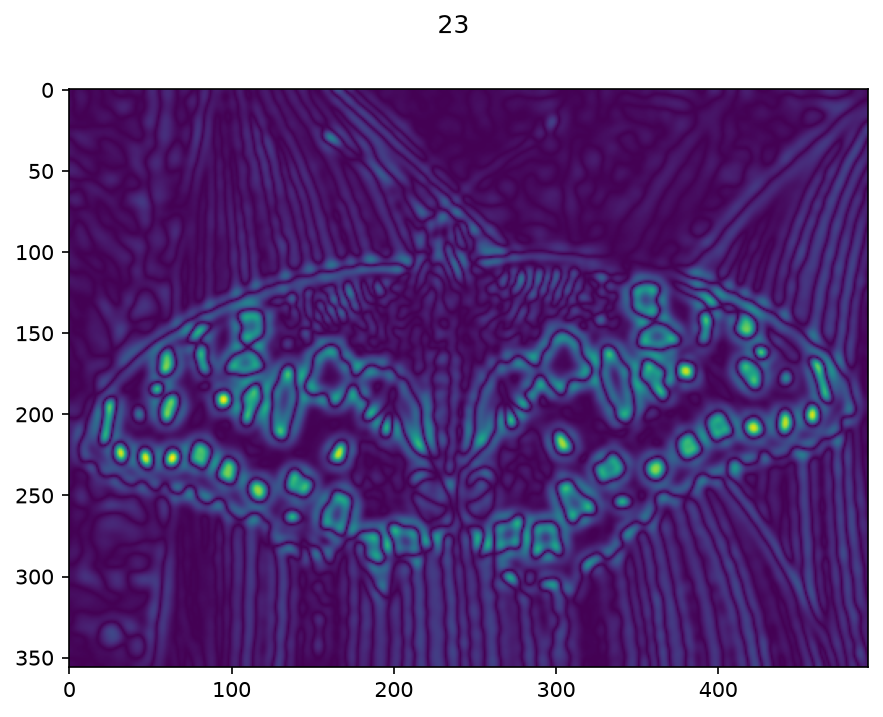

In [11]:
sigma = 2
k = 1.3
levels = 10

#student_code start

pyramid, all_sigmas = filters.get_log_pyramid(normalized_image, sigma, k, levels)
utils.show_plot(pyramid[:, :, 2], group_no='23', name='Scale_Space')

#student_code end

### 2. Blob detection

Perform the first step of the non-maximum suppression by setting the values in the scale space below a certain threshold to zero. Then, look for maxima in a defined local neighbourhood, in this case: the 26-connection. ***skimage.feature.peak_local_max(..)*** is useful to obtain local maxima. Complete method ***utils.show_blobs(..)*** and plot the blobs.


***Submission:*** Save the image including the blobs as **task1_blobs_full.png** (threshold around 0.3).

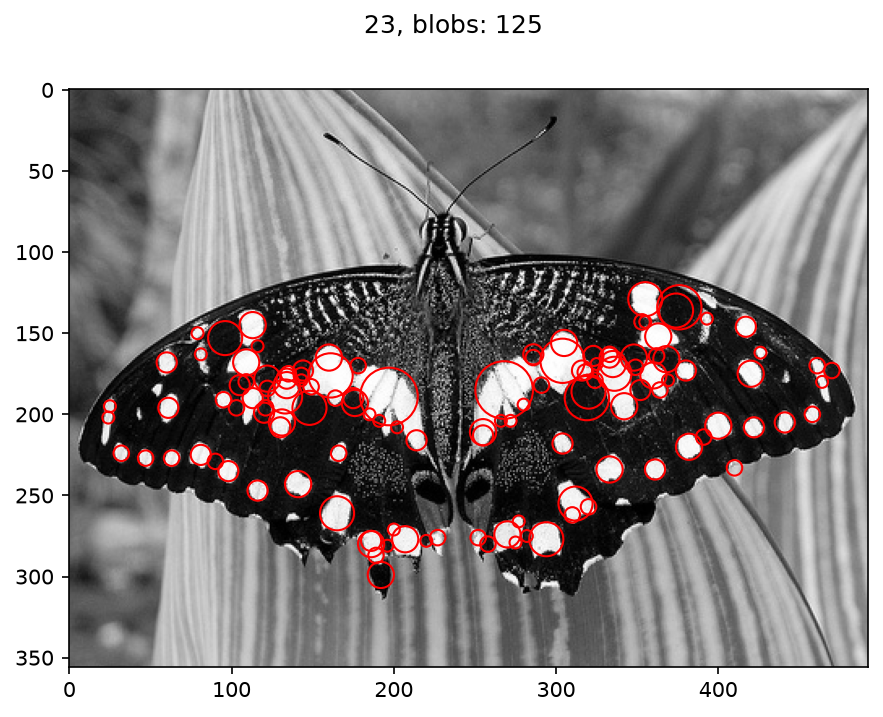

In [12]:
thres = 0.3

#student_code start

thresholded = pyramid.copy()
thresholded[thresholded < thres] = 0
peaks = peak_local_max(thresholded, footprint=np.ones((3, 3, 3), dtype=bool))

utils.show_blobs(img=normalized_image, peaks=peaks, all_sigmas=all_sigmas, group_no='23', name='Blobs')

#student_code end


### 3. Evaluation 

Apply the process to a half-sized version of the input image. Plot your results as well with ***utils.show_blobs(..)***.

_***HINT:***_
_cv2.resize(..)_


***Submission:*** Save the result as **task1_blobs_half.png**.

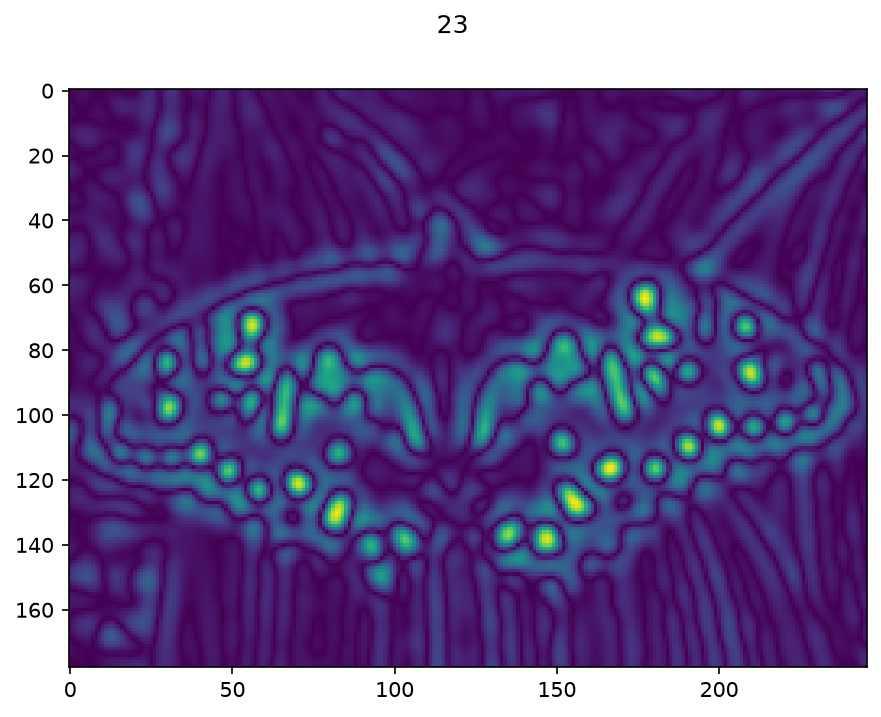

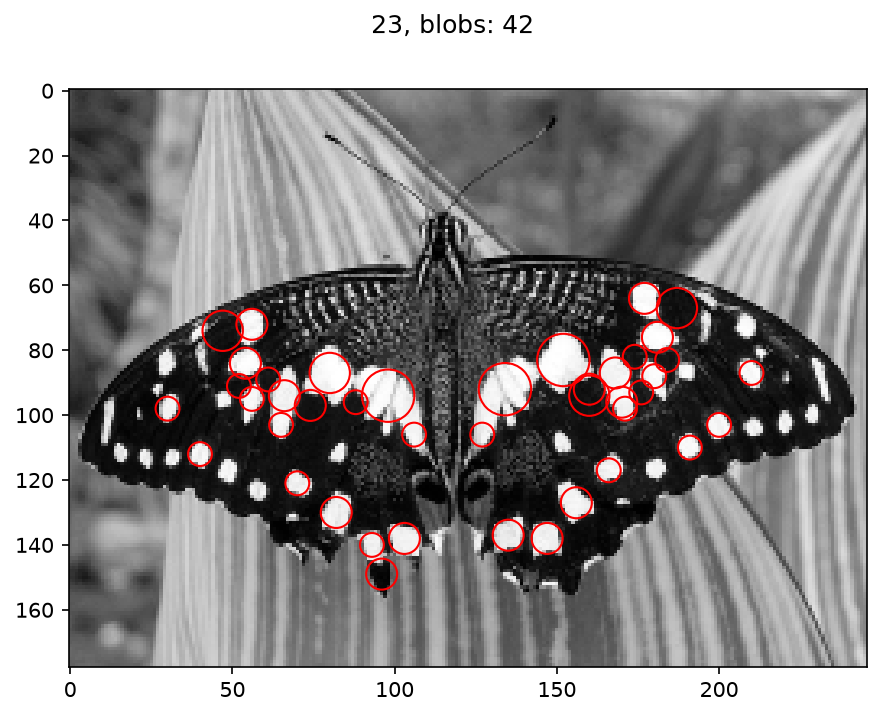

In [13]:
#student_code start

halfsize_image=cv2.resize(normalized_image, (0, 0), fx=0.5, fy=0.5)

h_pyramid, h_all_sigmas = filters.get_log_pyramid(halfsize_image, sigma, k, levels)
utils.show_plot(h_pyramid[:, :, 2], group_no='23', name='Scale_Space_halfsize')

h_thresholded = h_pyramid.copy()
h_thresholded[h_thresholded < thres] = 0
h_peaks = peak_local_max(h_thresholded, footprint=np.ones((3, 3, 3), dtype=bool))

utils.show_blobs(img=halfsize_image, peaks=h_peaks, all_sigmas=h_all_sigmas, group_no='23', name='Blobs_halfsize')

#student_code end

*** 
#### Taking a close look at the detected blobs on different image scales, is the method able to find blobs in a scale-invariant way? What could be reasons for observed errors or inaccurately detected blobs? 

There are less detected blobs. It is not scale-invariant. 
The filter-size is too big, therefore some smaller blobs are not detected. Reducing the filter-size will lead to more detection results, but still not the same as with the original size.
Also resizing an image results in information loss.

#### 3.1 LoG Response

Pick a detected keypoint and plot the response of the LoG for all scales in both image versions. The outcome should be a 2D plot where the x-axis represents the scale of the filter and the y-axis the filter response at the selected keypoint position. 

_***HINT:***_
_plt.plot(..)_

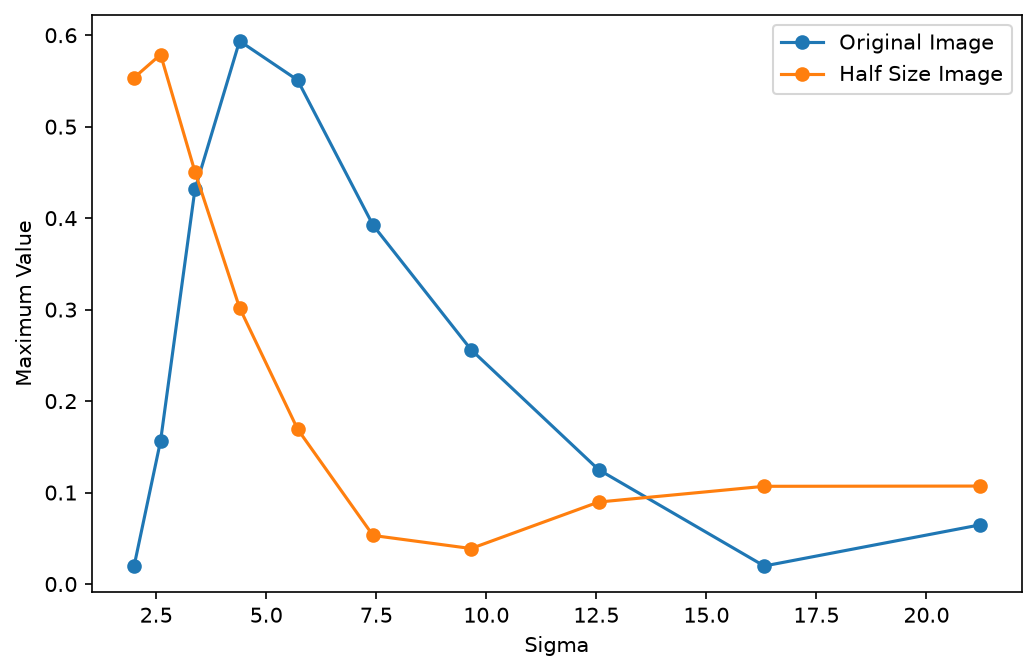

In [14]:
#student_code start

row, col, level = peaks[10]

plt.plot(all_sigmas[:, 0], pyramid[row, col, :],
         marker='o', label='Original Image')

plt.plot(h_all_sigmas[:, 0], h_pyramid[int(row / 2), int(col / 2), :],
         marker='o', label='Half Size Image')

plt.xlabel('Sigma')
plt.ylabel('Maximum Value')
plt.legend()
plt.show()

#student_code end

*** 
#### Describe and explain the difference between the two LoG response curves.

The highest value of the half image size is achieved at the point where is half the size.
Because of the half image size, a filter with a sigma with half the size will behave similarly as on the full image.

#### 3.2 Own Image

Import an image of your choice and apply the process once again. 


***Submission:*** Save the image including blobs with ***utils.show_blobs(..)*** as: **task1_blobs_own.png**

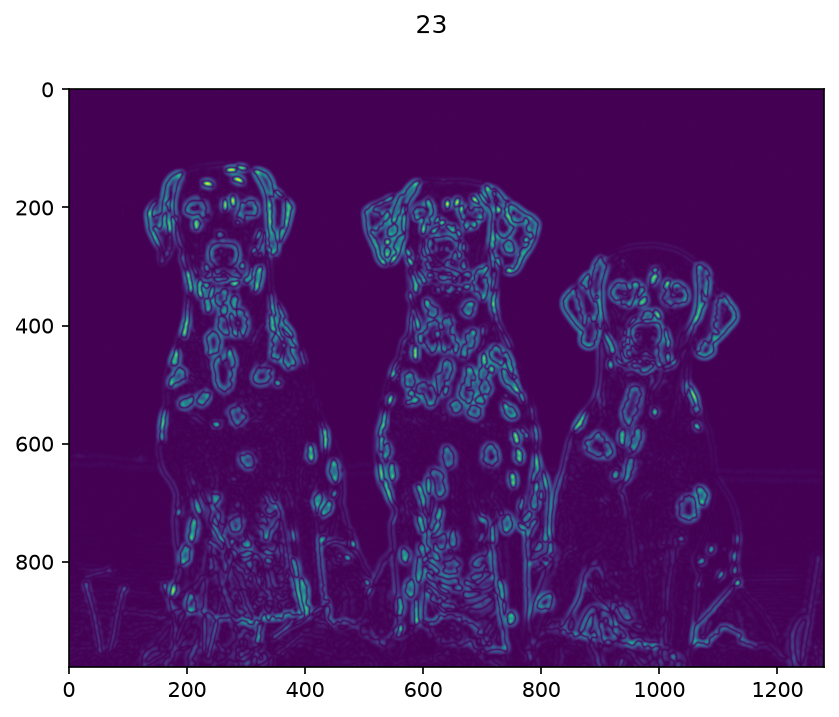

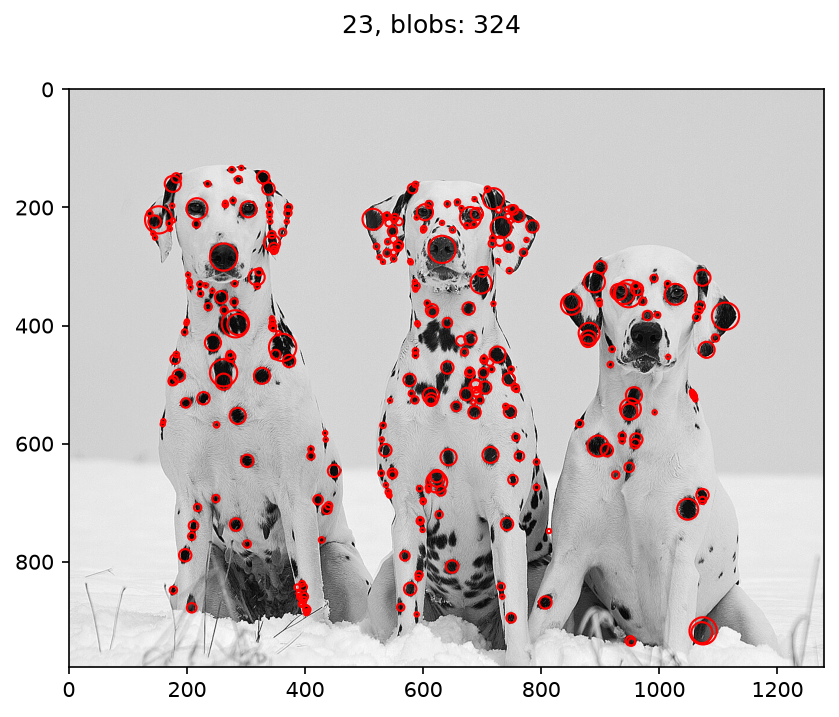

In [15]:
#student_code start

own_image = cv2.imread('data/dalmatian.jpg', cv2.IMREAD_GRAYSCALE)
own_normalized_image = cv2.normalize(
    own_image, None, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_64F)

own_pyramid, own_all_sigmas = filters.get_log_pyramid(own_normalized_image, sigma, k, levels)
utils.show_plot(own_pyramid[:, :, 2], group_no='23', name='Scale_Space_own')

own_thresholded = own_pyramid.copy()
own_thresholded[own_thresholded < thres] = 0
own_peaks = peak_local_max(own_thresholded, footprint=np.ones((3, 3, 3), dtype=bool))

utils.show_blobs(img=own_normalized_image, peaks=own_peaks, all_sigmas=own_all_sigmas, group_no='23', name='Blobs_own')

#student_code end